# 4. Последствия: жертвы и цунами

В управлении рисками ЧС принято разделять:

$$\text{Риск} = \text{Опасность} \times \text{Уязвимость} \times \text{Подверженность}$$

Ноутбук 3 оценивал **опасность** — частоту и силу землетрясений. Здесь мы соединяем
инструментальный каталог USGS с базой последствий NOAA и смотрим, от чего зависят потери.

**Вопросы:** (1) совпадают ли самые сейсмически активные и самые смертоносные зоны?
(2) что сильнее связано с числом жертв — магнитуда или глубина очага? (3) при каких
параметрах землетрясение вызывает цунами?

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from seismic import db, plots, stats

plots.setup_style()
pd.set_option("display.width", 160)

## 4.1. Опасность ≠ риск

In [2]:
display(Markdown(f"```sql\n{db.read_query('08_m7_impact_by_zone').strip()}\n```"))
impact = db.query("08_m7_impact_by_zone")
years = db.query("SELECT MAX(year) - MIN(year) + 1 AS y FROM events")["y"].iloc[0]
impact["m7_per_year"] = impact["n_m7"] / years
impact

```sql
-- Последствия землетрясений M≥7 (1973–2025) по зонам: LEFT JOIN каталога с NOAA
SELECT
    z.name                                                AS zone,
    COUNT(*)                                              AS n_m7,
    SUM(s.noaa_id IS NOT NULL)                            AS n_in_noaa,
    SUM(COALESCE(s.deaths, 0) > 0)                        AS n_fatal,
    ROUND(100.0 * SUM(COALESCE(s.deaths, 0) > 0) / COUNT(*), 1) AS fatal_pct,
    SUM(COALESCE(s.deaths, 0))                            AS deaths,
    SUM(s.tsunami_id IS NOT NULL)                         AS n_tsunami
FROM events AS e
JOIN zones  AS z USING (zone_id)
LEFT JOIN significant AS s ON s.usgs_event_id = e.event_id
WHERE e.mag >= 7.0
GROUP BY z.zone_id
ORDER BY deaths DESC;
```

,zone,n_m7,n_in_noaa,n_fatal,fatal_pct,deaths,n_tsunami,m7_per_year
0,"Гималаи, Центральная Азия, Китай",38,34,23,60.5,442358,3,0.716981
1,Карибский регион,6,6,5,83.3,318335,5,0.113208
2,Индонезия,73,41,27,37.0,239232,28,1.377358
3,Средиземноморье и Ближний Восток,23,23,20,87.0,152798,8,0.433962
4,Мексика и Центральная Америка,47,40,32,68.1,34443,30,0.886792
5,"Япония, Курилы, Камчатка",76,63,16,21.1,21651,54,1.433962
6,Филиппины и Тайвань,45,29,22,48.9,13123,20,0.849057
7,Новая Гвинея и Соломоновы о-ва,89,60,27,30.3,8411,36,1.679245
8,"Анды (Чили, Перу, Эквадор)",75,50,36,48.0,8018,23,1.415094
9,"Тонга, Фиджи, Вануату, Кермадек",137,77,4,2.9,226,61,2.584906


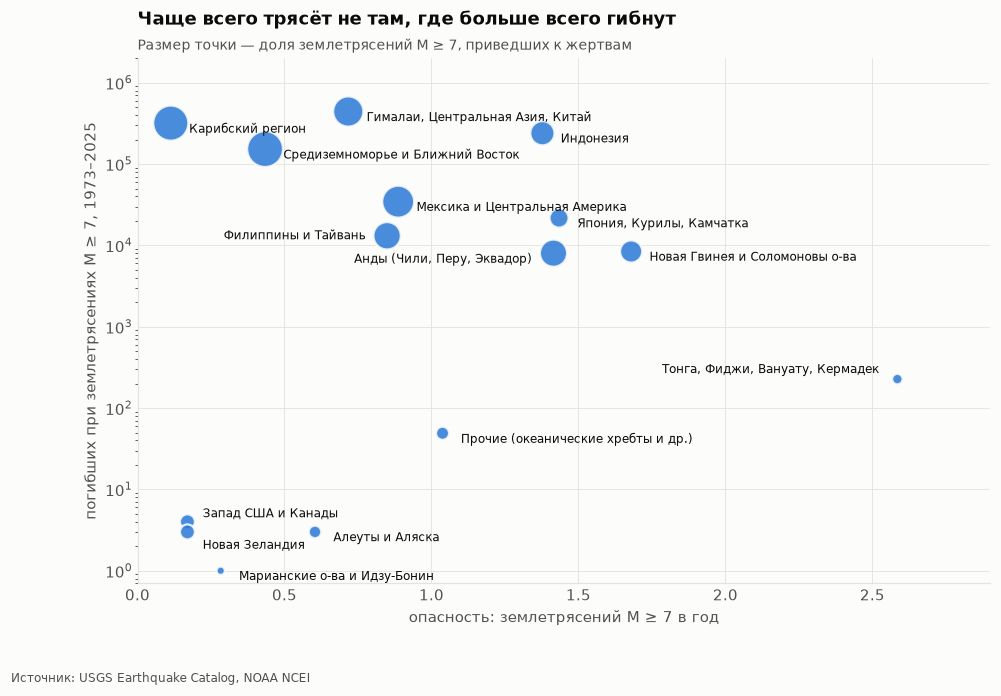

In [3]:
fig, ax = plt.subplots(figsize=(10, 6.2))
size = 30 + impact["fatal_pct"] * 6
ax.scatter(impact["m7_per_year"], impact["deaths"] + 1, s=size, color=plots.SERIES[0], alpha=0.85,
           edgecolors=plots.SURFACE, linewidths=1.5, zorder=3)
# смещения подписей подобраны вручную, чтобы подписи не накладывались
offsets = {"Тонга, Фиджи, Вануату, Кермадек": (-12, 6), "Анды (Чили, Перу, Эквадор)": (-14, -4),
           "Филиппины и Тайвань": (-14, 0), "Запад США и Канады": (10, 5), "Новая Зеландия": (10, -9)}
for _, row in impact.iterrows():
    dx, dy = offsets.get(row["zone"], (12, -4))
    ax.annotate(row["zone"], (row["m7_per_year"], row["deaths"] + 1), xytext=(dx, dy),
                textcoords="offset points", fontsize=8, color=plots.TEXT, va="center",
                ha="right" if dx < 0 else "left")
ax.set_yscale("log")
ax.set_xlim(0, 2.9)
ax.set_ylim(0.7, 2e6)
ax.grid(axis="x", visible=True)
ax.set_xlabel("опасность: землетрясений M ≥ 7 в год")
ax.set_ylabel("погибших при землетрясениях M ≥ 7, 1973–2025")
ax.set_title("Чаще всего трясёт не там, где больше всего гибнут")
plots.subtitle(ax, "Размер точки — доля землетрясений M ≥ 7, приведших к жертвам")
plots.source_note(fig)
plots.save(fig, "11_hazard_vs_impact")
plt.show()

Зона Тонга–Кермадек — сейсмически самая активная на Земле (≈ 2.6 события M ≥ 7 в год), но жертвы
единичны: очаги в океане и на глубине, население мало. Напротив, в Гималаях, Средиземноморье
и Карибском регионе сильные землетрясения в 4–20 раз реже, но именно там произошли катастрофы
Таншаня, Гаити, Кашмира, Турции. Причины — очаги под густонаселёнными районами на малой глубине
и уязвимая застройка.

## 4.2. Что определяет число жертв?

Берём все значимые землетрясения NOAA с известным числом погибших и считаем ранговую
корреляцию Спирмена (устойчива к выбросам и нелинейности; реализована через ранги pandas + NumPy).

In [4]:
sig = db.query("""
    SELECT s.noaa_id, s.year, s.country, s.mag, s.depth_km, s.deaths, s.intensity,
           s.tsunami_id IS NOT NULL AS has_tsunami, z.name AS zone
    FROM significant s LEFT JOIN zones z USING (zone_id)
    WHERE s.deaths > 0 AND s.mag >= 4.0
""")
print(f"{len(sig):,} землетрясений M ≥ 4 с жертвами, 1900–2025")


def spearman(x: pd.Series, y: pd.Series) -> float:
    mask = x.notna() & y.notna()
    return float(np.corrcoef(x[mask].rank(), y[mask].rank())[0, 1])


corr = pd.Series({
    "магнитуда": spearman(sig["mag"], sig["deaths"]),
    "глубина очага": spearman(sig["depth_km"], sig["deaths"]),
    "интенсивность (MMI)": spearman(sig["intensity"], sig["deaths"]),
    "год": spearman(sig["year"], sig["deaths"]),
}, name="ρ Спирмена с числом погибших").round(2)
corr.to_frame()

1,589 землетрясений M ≥ 4 с жертвами, 1900–2025


,ρ Спирмена с числом погибших
магнитуда,0.36
глубина очага,-0.04
интенсивность (MMI),0.49
год,-0.35


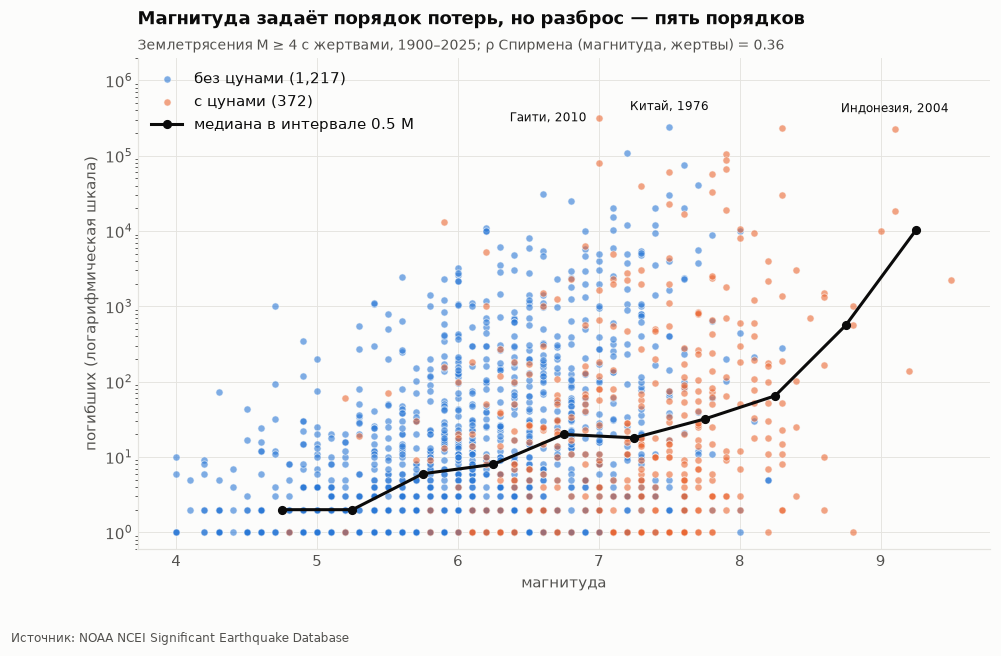

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.8))
groups = {False: ("без цунами", plots.SERIES[0]), True: ("с цунами", plots.SERIES[1])}
for flag, (label, color) in groups.items():
    sub = sig.loc[sig["has_tsunami"] == flag]
    ax.scatter(sub["mag"], sub["deaths"], s=22, color=color, alpha=0.6,
               edgecolors=plots.SURFACE, linewidths=0.6, label=f"{label} ({len(sub):,})")

# медиана погибших по бинам магнитуды
bins = np.arange(4.5, 9.6, 0.5)
sig["mag_bin"] = pd.cut(sig["mag"], bins)
med = sig.groupby("mag_bin", observed=True)["deaths"].median()
ax.plot([iv.mid for iv in med.index], med.to_numpy(), color=plots.TEXT, linewidth=2,
        marker="o", markersize=5, label="медиана в интервале 0.5 M")

callouts = {2010: (-8, 0, "right"), 1976: (0, 9, "center"), 2004: (0, 9, "center")}
for _, row in sig.nlargest(4, "deaths").loc[lambda d: d["year"].isin(callouts)].iterrows():
    dx, dy, ha = callouts[row["year"]]
    ax.annotate(f"{plots.COUNTRY_RU.get(row['country'], row['country'])}, {row['year']}",
                (row["mag"], row["deaths"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color=plots.TEXT, ha=ha, va="center" if dy == 0 else "bottom")
ax.set_yscale("log")
ax.set_ylim(0.6, 2e6)
ax.set_xlabel("магнитуда")
ax.set_ylabel("погибших (логарифмическая шкала)")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper left")
ax.set_title("Магнитуда задаёт порядок потерь, но разброс — пять порядков")
plots.subtitle(ax, f"Землетрясения M ≥ 4 с жертвами, 1900–2025; ρ Спирмена (магнитуда, жертвы) = {corr['магнитуда']:.2f}")
plots.source_note(fig, "Источник: NOAA NCEI Significant Earthquake Database")
plots.save(fig, "12_deaths_vs_magnitude")
plt.show()

Медианное число погибших растёт с магнитудой, однако при одной и той же магнитуде потери
различаются в миллион раз. Сильнее всего с жертвами связана **интенсивность** сотрясений
на поверхности (MMI, ρ ≈ 0.5) — она уже учитывает и магнитуду, и глубину, и грунты.

Отрицательная связь с **годом** (ρ ≈ −0.35) — не только успех сейсмостойкого строительства,
но и эффект отбора: в начале XX века в базу попадали в основном катастрофические события,
а сейчас регистрируются и землетрясения с единичными жертвами.

Глубина в целом с жертвами не связана (ρ ≈ 0), но это эффект смешения: сильные события в
среднем глубже. Проверим влияние глубины при фиксированной магнитуде (M 6.5–7.5).

In [6]:
mid = sig.loc[sig["mag"].between(6.5, 7.5)].copy()
mid["глубина"] = pd.cut(mid["depth_km"], [0, 20, 40, 70, 700],
                        labels=["0–20 км", "20–40 км", "40–70 км", "> 70 км"])
(mid.groupby("глубина", observed=True)["deaths"]
    .agg(событий="size", медиана="median", среднее="mean", максимум="max")
    .round(0))

,событий,медиана,среднее,максимум
глубина,,,,
0–20 км,210,42.0,3513.0,316000
20–40 км,157,18.0,3143.0,242769
40–70 км,62,4.0,144.0,6000
> 70 км,55,5.0,107.0,1641


При той же магнитуде очаги до 20 км в медиане уносят почти в 10 раз больше жизней, чем очаги
глубже 40 км: энергия сейсмических волн затухает, пока доходит до поверхности.

## 4.3. Когда землетрясение вызывает цунами?

In [7]:
display(Markdown(f"```sql\n{db.read_query('07_tsunami_by_magnitude').strip()}\n```"))
ts = db.query("07_tsunami_by_magnitude")
ts["p"], ts["lo"], ts["hi"] = stats.wilson_interval(ts["n_tsunami"].to_numpy(), ts["n_events"].to_numpy())
ts

```sql
-- Какая доля сильных неглубоких землетрясений вызывает цунами?
-- Каталог USGS (M≥6.5) связан с NOAA через significant.usgs_event_id;
-- разбивка по магнитуде (шаг 0.5) и классу глубины очага
WITH eq AS (
    SELECT
        e.event_id,
        CAST(e.mag * 2 AS INTEGER) / 2.0      AS mag_bin,      -- шаг 0.5
        e.depth_class,
        s.tsunami_id
    FROM events AS e
    LEFT JOIN significant AS s ON s.usgs_event_id = e.event_id
    WHERE e.mag >= 6.5
)
SELECT
    mag_bin,
    depth_class,
    COUNT(*)                                        AS n_events,
    SUM(tsunami_id IS NOT NULL)                     AS n_tsunami,
    ROUND(100.0 * SUM(tsunami_id IS NOT NULL) / COUNT(*), 1) AS tsunami_pct
FROM eq
GROUP BY mag_bin, depth_class
ORDER BY depth_class, mag_bin;
```

,mag_bin,depth_class,n_events,n_tsunami,tsunami_pct,p,lo,hi
0,6.5,глубокофокусное,137,0,0.0,0.000000,0.000000,0.027276
1,7.0,глубокофокусное,45,0,0.0,0.000000,0.000000,0.078654
2,7.5,глубокофокусное,13,0,0.0,0.000000,0.000000,0.228102
3,8.0,глубокофокусное,3,1,33.3,0.333333,0.061490,0.792345
4,6.5,мелкофокусное,1227,141,11.5,0.114914,0.098259,0.133974
5,7.0,мелкофокусное,376,158,42.0,0.420213,0.371374,0.470665
6,7.5,мелкофокусное,151,111,73.5,0.735099,0.659516,0.799018
7,8.0,мелкофокусное,30,30,100.0,1.000000,0.886483,1.000000
8,8.5,мелкофокусное,4,4,100.0,1.000000,0.510100,1.000000
9,9.0,мелкофокусное,2,2,100.0,1.000000,0.342372,1.000000


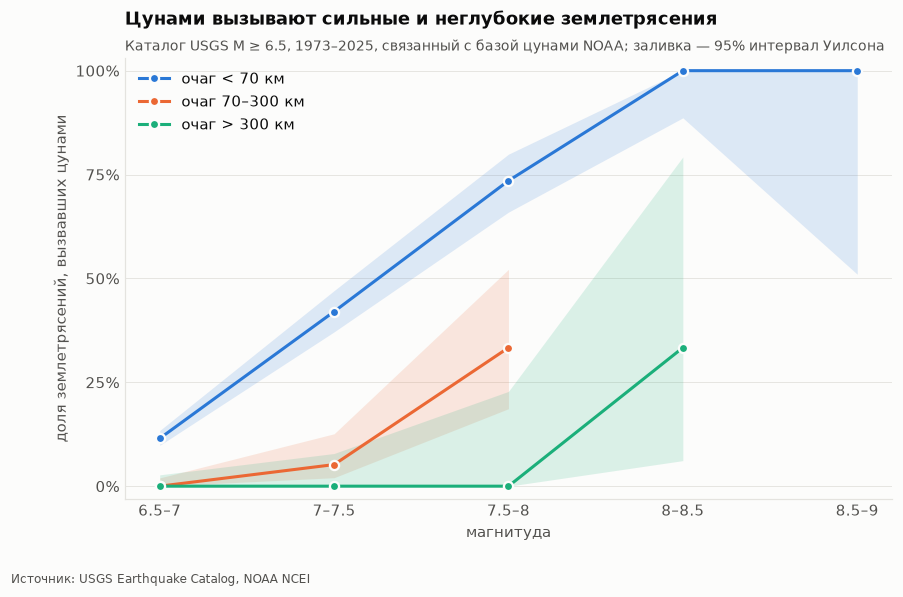

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.2))
styles = {"мелкофокусное": ("очаг < 70 км", plots.SERIES[0]),
          "промежуточное": ("очаг 70–300 км", plots.SERIES[1]),
          "глубокофокусное": ("очаг > 300 км", plots.SERIES[2])}
for cls, (label, color) in styles.items():
    sub = ts.loc[(ts["depth_class"] == cls) & (ts["n_events"] >= 3)]   # бины из 1–2 событий не показываем
    x = sub["mag_bin"] + 0.25
    ax.fill_between(x, sub["lo"] * 100, sub["hi"] * 100, color=color, alpha=0.15, linewidth=0)
    ax.plot(x, sub["p"] * 100, color=color, marker="o", markersize=6,
            markeredgecolor=plots.SURFACE, markeredgewidth=1.5, label=label)
ax.set_xticks(np.arange(6.75, 8.8, 0.5), ["6.5–7", "7–7.5", "7.5–8", "8–8.5", "8.5–9"])
ax.set_yticks(range(0, 101, 25), [f"{v}%" for v in range(0, 101, 25)])
ax.set_ylim(-3, 103)
ax.set_xlabel("магнитуда")
ax.set_ylabel("доля землетрясений, вызвавших цунами")
ax.legend(loc="upper left")
ax.set_title("Цунами вызывают сильные и неглубокие землетрясения")
plots.subtitle(ax, "Каталог USGS M ≥ 6.5, 1973–2025, связанный с базой цунами NOAA; заливка — 95% интервал Уилсона")
plots.source_note(fig)
plots.save(fig, "13_tsunami_probability")
plt.show()

Доля цунамигенных событий среди неглубоких землетрясений растёт с ~12% при M6.5–7 до 100%
при M ≥ 8. Глубокие очаги (> 300 км) цунами практически не вызывают, сколь бы сильными они
ни были: деформация морского дна мала. Именно поэтому системы предупреждения о цунами
в первые минуты опираются на две величины — магнитуду и глубину очага.

Оговорка: в выборке есть и континентальные землетрясения, которые не могут вызвать цунами,
поэтому для чисто морских событий доли будут ещё выше.

## 4.4. Самые смертоносные землетрясения

In [9]:
display(Markdown(f"```sql\n{db.read_query('09_deadliest_events').strip()}\n```"))
db.query("09_deadliest_events", {"top_n": 15})

```sql
-- Самые смертоносные землетрясения XX–XXI вв. и высота вызванных ими цунами
SELECT
    s.year,
    s.country,
    s.location,
    s.mag,
    s.depth_km,
    s.deaths,
    t.max_water_height_m                        AS tsunami_height_m,
    RANK() OVER (ORDER BY s.deaths DESC)        AS rank_deaths
FROM significant AS s
LEFT JOIN tsunamis AS t ON t.tsunami_id = s.tsunami_id
WHERE s.deaths IS NOT NULL
ORDER BY s.deaths DESC
LIMIT :top_n;
```

,year,country,location,mag,depth_km,deaths,tsunami_height_m,rank_deaths
0,2010,Haiti,HAITI: PORT-AU-PRINCE,7.0,13.0,316000,NaN,1
1,1976,China,CHINA: NE: TANGSHAN,7.5,23.0,242769,NaN,2
2,1920,China,"CHINA: GANSU PROVINCE, SHANXI PROVINCE",8.3,25.0,235502,0.75,3
3,2004,Indonesia,INDONESIA: SUMATRA: ACEH: OFF WEST COAST,9.1,30.0,227899,50.90,4
4,1948,Turkmenistan,TURKMENISTAN: ASHKHABAD,7.2,18.0,110000,NaN,5
5,1923,Japan,"JAPAN: TOKYO, YOKOHAMA",7.9,35.0,105385,13.00,6
6,2008,China,CHINA: SICHUAN PROVINCE,7.9,10.0,87652,NaN,7
7,1908,Italy,"ITALY: MESSINA, SICILY, CALABRIA",7.0,40.0,80000,NaN,8
8,2005,Pakistan,"PAKISTAN: MUZAFFARABAD, URI, ANANTNAG, BARAMULA",7.6,15.0,76213,NaN,9
9,1970,Peru,"PERU: NORTHERN, PISCO, CHICLAYO",7.9,43.0,66794,0.46,10


**Выводы ноутбука:**
1. Сейсмическая активность и число жертв почти не связаны на уровне зон: самая активная зона
   (Тонга–Кермадек) — одна из наименее смертоносных.
2. Магнитуда задаёт порядок потерь (ρ ≈ 0.36), но при равной магнитуде неглубокие очаги
   (до 20 км) в медиане дают почти в 10 раз больше жертв, чем очаги глубже 40 км.
3. Вероятность цунами определяется магнитудой и глубиной: при M ≥ 8 и очаге до 70 км цунами возникает почти всегда.